# Fine-Tunning

Este tutorial es una versión recortada y adaptada de: https://huggingface.co/docs/transformers/v4.47.1/es/training 

El entrenamiento de un modelo partiendo de una inicialización aleatoria de los parámetros del mismo es una tarea muy costosa computacionalmente. Especialmente para modelos con arquitectura de tipo Transformers, donde los requerimientos computacionales pueden implicar el uso de cientos de GPUs durante semanas, e incluso más. Por ello, es más habitual en entornos modestos partir de una inicialización de los pesos procedente de un modelo preentrenado para una tarea más general que aquella que se quiere acometer. 

Este proceso, que tiene unos requerimientos computacionales mucho más modestos recibe el nombre de **fine-tuning**. En este caso, los pesos ya están inicializados para resolver una tarea más genérica, pero se expone durante varios ciclos de entrenamiento a un *dataset* más pequeño que el inicial, pero diseñado para que el modelo aprenda una tarea más específica. En este caso, vamos a realizar la clasificación de noticias en tres categorías: deportes, cultura y política.

Este notebook va a demostrar cómo realizar dicho proceso utilizando la clase Trainer de la librería Transformers.

In [8]:
import torch
from torch.utils.data import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
model_id = 'distilbert-base-uncased'
#model_id = 'bert-base-multilingual-cased'

tokenizer = AutoTokenizer.from_pretrained(model_id)

model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=3)

class TextClassificationDataset(Dataset):
    def __init__(self, filename, tokenizer, max_length=256):
        self.tokenizer = tokenizer
        self.sentences = []
        self.labels = []
        self.max_length = max_length

        with open(filename, 'r', encoding='utf-8') as file:
            for line in file:
                start = line.find('"')
                end = line.find('"', start + 1)
                sentence = line[start + 1:end].strip()
                label = int(line[end + 1:].strip()[-1])

                # Crear los tokens para alimentar a BERT de HuggingFace
                tokens = self.tokenizer.encode_plus(sentence, add_special_tokens=True, max_length=self.max_length, truncation=True, padding='max_length', return_tensors='pt')
                self.sentences.append(tokens)
                self.labels.append(label)

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx):
        # 1. Copia de forma dinámica solo las claves que el tokenizador REALMENTE generó
        item = {key: val.squeeze() for key, val in self.sentences[idx].items()}
        
        # 2. Añade la etiqueta correspondiente
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        
        #item = {key: val for key, val in self.sentences[idx].items()}
        #item['labels'] = torch.tensor(self.labels[idx])
        #item['input_ids'] = item['input_ids'].squeeze()
        #item['attention_mask'] = item['attention_mask'].squeeze()
        #item['token_type_ids'] = item['token_type_ids'].squeeze()
        
        return item
            

# Creamos el conjunto de datos
dataset = TextClassificationDataset('data/dataset_clas_texto.txt', tokenizer)

# Separamos el conjunto de datos en entrenamiento y validación
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## Entrenamiento

Usaremos el objeto Trainer de la librería transformers para entrenar nuestro modelo. Para ello, necesitamos el modelo, el tokenizador, los datos de entrenamiento y los datos de validación. Todos los parámetros que necesitamos para el entrenamiento están definidos en el objeto TrainingArguments.

In [11]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="test_trainer",
    num_train_epochs=2,
    logging_steps=1,
    logging_strategy='steps'
)

trainer = Trainer(
    model=model,
    tokenizer=tokenizer,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)
print("Iniciando entrenamiento ...")
trainer.train()

/tmp/ipykernel_10570/2941388833.py:10: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Iniciando entrenamiento ...


/home/roberto/.virtualenvs/transformers/lib/python3.12/site-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss
1,1.076500
2,1.102800
3,1.124500
4,1.089200
5,1.079700
6,1.052900
7,1.055000
8,1.128500
9,1.068700
10,1.081700


TrainOutput(global_step=20, training_loss=1.0805647134780885, metrics={'train_runtime': 82.0143, 'train_samples_per_second': 1.951, 'train_steps_per_second': 0.244, 'total_flos': 10852008099840.0, 'train_loss': 1.0805647134780885, 'epoch': 2.0})

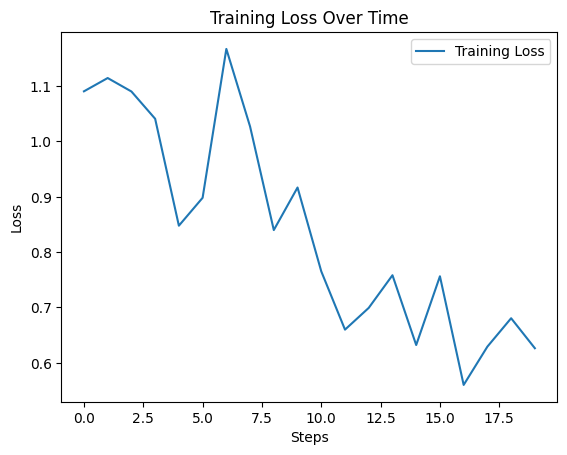

In [7]:
import os
import matplotlib.pyplot as plt
import json

def plot_training_loss(log_dir):
    history = trainer.state.log_history
    training_loss = [log['loss'] for log in history if 'loss' in log]

    plt.plot(training_loss, label='Training Loss')
    plt.xlabel('Steps')
    plt.ylabel('Loss')
    plt.title('Training Loss Over Time')
    plt.legend()
    plt.show()

plot_training_loss('./logs')

## Inferencia

Vamos a probar nuestro modelo con algunas noticias de ejemplo.

In [ ]:
sentences = []
labels = []

with open('data/dataset_clas_texto_test.txt', 'r', encoding='utf-8') as file:
    for line in file:
        start = line.find('"')
        end = line.find('"', start + 1)
        sentence = line[start + 1:end].strip()
        label = int(line[end + 1:].strip()[-1])
        sentences.append(sentence)
        labels.append(label)

clases = {
    0: 'Deportes',
    1: 'Cultura',
    2: 'Política'
}

device = torch.device("cpu")
model = model.to(device)
aciertos = 0
for sentence, label in zip(sentences, labels):
    tokens = tokenizer.encode_plus(sentence, add_special_tokens=True, max_length=256, truncation=True, padding='max_length', return_tensors='pt')
    tokens.to(device)
    outputs = model(**tokens)
    y_pred = torch.argmax(outputs.logits).item()
    y = label
    if y_pred == y:
        aciertos += 1
    print(f"{sentence} -> {clases[y]}, {clases[y_pred]}")

print("-"*50)  
print(f"Aciertos: {aciertos}, Total: {len(sentences)}, Accuracy: {aciertos / len(sentences)}")

## Data Collators
En Hugging Face, los Data Collators son herramientas que toman una lista de muestras de tu dataset y las empaquetan, rellenan con espacios (padding) y preparan en forma de lotes (batches) listos para que el modelo los procese eficientemente.

### 1. DataCollatorWithPadding
Uso: Prepara batches de datos, asegurando que todos los inputs tengan la misma longitud mediante padding.
Se pasa como argumento a DataLoader para manejar el batching de manera eficiente.

### 2. DataCollatorForLanguageModeling
Sirve para entrenar modelos de lenguaje puro (que aprenden la estructura de un idioma). Su comportamiento cambia drásticamente según el parámetro mlm:

* Si mlm=True (Masked Language Modeling - Tipo BERT): El collator ocultará o "enmascarará" aleatoriamente algunas palabras de la frase (sustituyéndolas por el token [MASK]) y creará las etiquetas necesarias para que el modelo intente adivinar qué palabras faltan.
* Si mlm=False (Causal Language Modeling - Tipo Llama/GPT): El collator preparará los textos para que el modelo intente predecir siempre la siguiente palabra de la secuencia. Automáticamente desplaza los textos un lugar a la derecha para crear las etiquetas de entrenamiento (labels).

### 3. DataCollatorForSeq2Seq
Sirve para entrenar modelos de Secuencia a Secuencia (como T5 o BART), donde tienes un texto de entrada completo y esperas un texto de salida totalmente diferente (por ejemplo, traducción automática de inglés a español o resúmenes de texto).

* Su función clave: A diferencia del anterior, este collator tiene que gestionar dos secuencias distintas a la vez (la pregunta/origen y la respuesta/destino). Además de aplicar relleno dinámico a ambas partes, se encarga de ignorar los tokens de relleno del destino reemplazándolos por el ID -100, asegurando que el modelo no sea penalizado matemáticamente por calcular pérdidas en los espacios vacíos.

## Fine-Tunning
Vamos, por tanto, a implementar un ejemplo que nos permita entender cómo funciona T5 y cómo podemos utilizarlo para tareas de procesamiento de lenguaje natural propias. En este caso, utilizaremos el modelo T5 Base para realizar la transcripción de un número representado con sus dígitos a sus palabras en inglés. Por ejemplo, si el número es "123", la transcripción sería "one hundred twenty-three". Lo haremos en inglés en lugar de español para aprovechar la capacidad de T5 de trabajar con texto en inglés y porque, en tareas de traducción, el modelo solo ha sido entrenado en alemán, francés y rumando, además del inglés.

### Importamos las librerías necesarias para crear el dataset.

In [ ]:
from datasets import load_dataset, DatasetDict

# Cargamos el dataset desde un archivo CSV
dataset = load_dataset('csv', data_files='data/numbers.csv')

# Como el dataset no está dividido en entrenamiento y prueba, lo dividimos manualmente
train_test_split = dataset['train'].train_test_split(test_size=0.1)  # 90% entrenamiento, 10% prueba

dataset = DatasetDict({
    'train': train_test_split['train'],
    'test': train_test_split['test']
})
dataset['train'][42]

Recuerdas que antes vimos que el input del dataset estaba en formato entero. Para poder utilizarlo con el modelo T5, necesitamos convertirlo a texto. Además, queremos añadir a cada ejemplo la tarea específica que queremos que el modelo realice. En este caso, la tarea es "number to text". Para todo esto vamos a crear la función add_task. Fíjate que numbers puede ser tanto un número entero como una lista de números enteros.

In [ ]:
def add_task(numbers):
    if isinstance(numbers, int):
        return "number to text: " + str(numbers)
    else:
        res = []
        for number in numbers:
            text = str(number)
            text = "number to text: " + text
            res.append(text)
        return res

add_task([123456789, 111111111, 987654321])

Veamos qué aspecto tiene un conjunto de ejemplos antes y después de aplicar la función preprocess_function.

In [ ]:
def preprocess_function(examples):
    number_ids = add_task(examples['input_text'])
    text_input = tokenizer(number_ids, truncation=True, padding="max_length", max_length=15)
    labels = tokenizer(examples['output_text'], truncation=True, padding="max_length", max_length=32)

    return {
        'input_ids': text_input['input_ids'],
        'labels': labels['input_ids']
    }

print(dataset['train'][:3])
print("------------------------------")
print(preprocess_function(dataset['train'][:3]))

Entrenamos el modelo base

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir='./results',  # output directory
    num_train_epochs=3,  # total number of training epochs
    per_device_train_batch_size=16,  # batch size per device during training
    per_device_eval_batch_size=64,   # batch size for evaluation
    warmup_steps=500,  # number of warmup steps for learning rate scheduler
    weight_decay=0.01,  # strength of weight decay
    logging_dir='./logs',  # directory for storing logs
    logging_steps=10,
)

trainer = Trainer(
    model=model,  # the instantiated 🤗 Transformers model to be trained
    args=training_args,  # training arguments, defined above
    train_dataset=dataset['train'].map(preprocess_function, batched=True),  # training dataset
    eval_dataset=dataset['test'].map(preprocess_function, batched=True),  # evaluation dataset
)

trainer.train()

Lo probamos

In [ ]:
input_ids = tokenizer("number to text: 1000", return_tensors="pt").input_ids.to('mps')
outputs = model.generate(input_ids, max_length=50, num_beams=1)
output_text = tokenizer.decode(outputs[0], skip_special_tokens=True)

print(output_text)

Existen dos vías más complicadas para realizar el mismo proceso, pero que a cambio proporcionan más control sobre el mismo.

- Fine-tuning con Keras: [Ejemplo](https://huggingface.co/docs/transformers/v4.47.1/es/training#fine-tuning-con-keras)
- Fine-tuning con Pytorch Nativo: [Ejemplo](https://huggingface.co/docs/transformers/v4.47.1/es/training#fine-tune-en-pytorch-nativo)

## Fine-Tuned Embedding With Contrastive Learning
Extraído de la [página](https://medium.com/@roytalman_7701/fine-tuned-embedding-with-contrastive-learning-71da7b57164d) es un ejemplo de como tunear los embeddings obtenidos de un modelo derivado de SBERT para diferenciar subcategorías de dominios muy específicos. Por  ejemplo:
- 'sci.space'
- 'sci.med'
- 'sci.electronics'
- 'comp.os.ms-windows.misc'
- 'comp.sys.ibm.pc.hardware'
- 'comp.sys.mac.hardware'

Vamos a entrenar una red FFN para mapear los embeddings obtenidos por el modelo ‘Alibaba-NLP/gte-base-en-v1.5’ a unos nuevos embeddings utilizando aprendizaje por contraste. El aprendizaje por contraste intenta que los ejemplos pertenecientes a la misma clase tengan un embeddings más parecidos que los embeddings pertenecientes a clases distintas. La función de pérdida es del estilo:
$$
\sum_{i=0}^N \frac{\max(C_{n\_i}-C_{p\_i}+M,0)}{N}
$$
Donde $C_{n\_i}$ y $C_{p\_i}$ es el coseno del ángulo entre los embeddings de los pares negativos y los positivos respectivamente y M es una constante. En la [página](https://github.com/roytalman/Deep_contrastive_embedding) puedes descargar las librerías que implementan la función de pérdida.

In [ ]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer
from tqdm import tqdm
import torch
# local dependencies from git repository https://github.com/roytalman/Deep_contrastive_embedding
from contrastive import Contrastive_loss
from utils import plot_tsne,Net_embed,finetune_embeddig

# Define the categories we want to classify
categories = ['sci.space', 'sci.med','sci.electronics',
'comp.os.ms-windows.misc','comp.sys.ibm.pc.hardware','comp.sys.mac.hardware']

# Fetch the training dataset
newsgroups_train = fetch_20newsgroups(subset='train', categories=categories)
# Fetch the testing dataset
newsgroups_test = fetch_20newsgroups(subset='test', categories=categories)
# dump 90% of data
X_train,X_dump,y_train,y_dump = train_test_split(newsgroups_train.data, newsgroups_train.target,train_size=0.1,random_state=0)

X_test,X_dump,y_test,y_dump =  train_test_split(newsgroups_test.data, newsgroups_test.target,train_size=0.1,random_state=0)

Vamos a entrenar el modelo con el 10% de las noticias (40) obtenidas de un grupo de noticias en inglés y para medir la eficacia de los embeddings vamos a entrenar un clasificador por Regresión Logística y ver que resultados alcanza con esos embeddings. La función fit_predict_embedding entrena el clasificador 

In [ ]:
def fit_predict_embedding(embed_train,y_train,embed_test,y_test,target_names  ):
    clf = LogisticRegression(max_iter=10000)
    # Train the model on embedding:
    clf.fit(embed_train, y_train)
    # Make predictions on the test data:
    predicted = clf.predict(embed_test)
    #print performance report
    report = classification_report(y_test, predicted, target_names=newsgroups_test.target_names)
    print("Classification Report:\n", report)

Primero vamos a ver que exactitud alcanza el clasificador con los embeddings originales cuya dimensión es 768.

In [ ]:
# load model
model = SentenceTransformer('Alibaba-NLP/gte-base-en-v1.5', trust_remote_code=True)
embedding_mat_train = np.zeros((len(X_train),768))
embedding_mat_test = np.zeros((len(X_test),768))

# extract embedding:
for i in tqdm(range(len(X_train))):
    embedding_mat_train[i,:] = model.encode(X_train[i])

for i in tqdm(range(len(X_test))):
    embedding_mat_test[i,:] = model.encode(X_test[i])

# predict using gte embedding:
fit_predict_embedding(embedding_mat_train,y_train,embedding_mat_test,y_test,newsgroups_test.target_names  )

Ahora entrenamos la red FFN para mapear a un espacio de embeddings de dimensión 32. Calculamos los nuevos embeddings y con estos nuevos embeddings entrenamos de nuevo el clasificador logístico

In [ ]:
# train neural network using deep contrastive learnig  
net = finetune_embeddig(embedding_mat_train, y_train,N_epoch=15,out_dim=32, verbose=True,drop_prob = 0.3,hidden_dim = 256,margin=0.2)
# calculate test data embedding and Tsne
net.eval()
embedding_out_test = net(torch.from_numpy(embedding_mat_test).float()).detach().numpy()

embedding_out_train = net(torch.from_numpy(embedding_mat_train).float()).detach().numpy()
# classification with new embedding:
fit_predict_embedding(embedding_out_train,y_train,embedding_out_test, y_test,newsgroups_test.target_names  )